<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/kalman/notebooks/kalman_quadrotor_quaternions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

*O Filtro de Kalman para Cientistas da Computação* · [← guia da série](kalman_guia_da_serie.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/kalman/notebooks/kalman_guia_da_serie.ipynb)) · [repositório](https://github.com/saulobortolon/Quaternios-Kalman-CC) · série irmã: [*Números, movimento e Kalman*](../../dominios/notebooks/X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb))

# Kalman para um quadrotor: quaternions, dual quaternions e quaternions tridentes

## O mesmo filtro, quatro maneiras de medir o erro, e por que só uma delas aguenta um drone perdido

**Pergunta que responde.** Um drone estima a própria atitude, velocidade e posição a partir de uma IMU (giroscópio e acelerômetro) e de medidas ocasionais de posição ou de pose. Que objeto matemático deve guardar esse estado: um quaternion mais dois vetores, um dual quaternion mais a velocidade, ou um único **quaternion tridente**? E isso faz diferença no filtro de Kalman?

**Resposta curta, que o notebook demonstra.**
- O filtro é **sempre o mesmo** (um ESKF, o filtro de estado de erro do notebook 5). O que muda é **onde o erro mora**, isto é, a operação $\boxplus$ que soma uma correção ao estado.
- Com erros iniciais pequenos, as quatro escolhas dão **os mesmos números**.
- Com um erro de guinada grande e só GPS, a escolha decide se o filtro continua **honesto** e, no limite, se o drone se encontra. As versões com o **quaternion tridente** convergem em 23 de 24 simulações com 150° de erro e declaram uma incerteza compatível com o erro real. Com quaternion + vetores, já a partir de 45° o filtro se declara mais certo do que está, e a 150° só converge em 5 de 12. O **dual quaternion** + velocidade fica no meio do caminho (10 de 12, mas igualmente otimista).
- O motivo: com o tridente, a equação do erro **não depende da estimativa**, e um estimador ruim não contamina a própria linearização. O dual quaternion acopla rotação e posição, mas deixa a **velocidade** do lado de fora, e é justamente a velocidade que o acelerômetro integra.

**Lugar na série.** Continua o notebook 5 (`kalman_notas_im_kf_ekf_eskf_iekf_ieskf`), seções 5 e 7: o ESKF na atitude, com $\mathrm{Exp}$, $\mathrm{Log}$ e $\boxplus$, agora estendido à pose completa de um corpo rígido.

**Pré-requisitos.** Quaternions (rotação de vetores, produto de Hamilton) e dual quaternions (pose como $\hat q=q+\varepsilon\,\tfrac12 t\,q$), já vistos em aula; o ESKF do notebook 5.

**Textos acompanhados**
- W. Ouyang, Y. Wu, *A Trident Quaternion Framework for Inertial-based Navigation*, Parte I (representação; *IEEE Trans. Aerospace and Electronic Systems* 58(3):2409–2420, 2022; arXiv:2102.12217) e Parte II (modelos de erro e alinhamento; arXiv:2102.12220). **São a base das seções 2, 3 e 6.**
- N. Filipe, M. Kontitsis, P. Tsiotras, *Extended Kalman Filter for Spacecraft Pose Estimation Using Dual Quaternions*, JGCD, 2015. Base da versão com dual quaternion.
- S. Incicco, J. I. Giribet, L. Colombo, *Enhanced UAV Navigation Systems through Sensor Fusion with Trident Quaternions* (arXiv:2504.14133). O tridente num multirrotor real, com GPS.
- H. Jeon et al., *Quaternion-Based Iterative Extended Kalman Filter for Sensor Fusion of Vision Sensor and IMU in 6-DOF Displacement Monitoring*, IEEE Sensors Journal, 2022. Seção 7.
- C. Böhm et al., *Combined System Identification and State Estimation for a Quadrotor UAV*, ICRA 2021. Trajetória de Lissajous e seção 8.

Os textos não são reproduzidos aqui; as equações usadas são reescritas na notação da série, e as afirmações dos artigos são conferidas por simulação.

**Roteiro**
1. Por que um quaternion não basta para um drone
2. Três álgebras: quaternion, dual quaternion e quaternion tridente
3. A navegação inercial numa única equação de tridentes
4. O quadrotor simulado
5. Um filtro, quatro $\boxplus$
6. Experimento 1: medidas de pose a 10 Hz e a 0,5 Hz
7. Experimento 2: só GPS, com a guinada errada
8. O quaternion dentro do estado (Jeon et al.)
9. Dos sensores aos rotores (Böhm et al.)
10. O que levar deste notebook
11. Exercícios
12. Referências

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import expm

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

N_MC = 12          # simulações de Monte Carlo por configuração (12 → ~6 min no total; 4 → ~2 min)

def confere(nome, a, b, tol=1e-8, relativo=False):
    a, b = np.asarray(a, float), np.asarray(b, float)
    erro = np.max(np.abs(a - b)) / (np.max(np.abs(b)) if relativo else 1.0)
    print(f"{'OK ' if erro < tol else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert erro < tol, nome

def jacobiano_numerico(f, x, eps=1e-6):
    x = np.asarray(x, float)
    return np.column_stack([(np.asarray(f(x + e)) - np.asarray(f(x - e))) / (2 * eps) for e in np.eye(x.size) * eps])

---
# 1. Por que um quaternion não basta para um drone

Num drone, o filtro de navegação é guiado pela **IMU**, a centenas de amostras por segundo:
- o **giroscópio** mede a velocidade angular $\boldsymbol\omega$ no corpo; integrada, dá a **atitude** $\mathbf R$ (ou o quaternion $q$);
- o **acelerômetro** mede a **força específica** $\mathbf a=\mathbf R^\top(\ddot{\mathbf p}-\mathbf g)$, isto é, a aceleração sem a gravidade, no corpo. Girada para o mundo e somada à gravidade, ela integra a **velocidade** $\mathbf v$, que por sua vez integra a **posição** $\mathbf p$.

Em tempo contínuo,

$$\dot{\mathbf R}=\mathbf R\,[\boldsymbol\omega]_\times,\qquad \dot{\mathbf v}=\mathbf R\,\mathbf a+\mathbf g,\qquad \dot{\mathbf p}=\mathbf v .$$

O estado mínimo é, portanto, o terno $(\mathbf R,\mathbf v,\mathbf p)$: **9 graus de liberdade**. Três escolhas de "recipiente" para ele:

| escolha | o que guarda | grupo | graus de liberdade no grupo |
|---|---|---|---|
| quaternion + dois vetores | $q$; $\mathbf v$ e $\mathbf p$ soltos | $SO(3)\times\mathbb R^6$ | 3 (+6 vetoriais) |
| dual quaternion + um vetor | $\hat q=q+\varepsilon\,\tfrac12\mathbf p\,q$; $\mathbf v$ solto | $SE(3)\times\mathbb R^3$ | 6 (+3 vetoriais) |
| quaternion tridente | $q+\varepsilon_1\tfrac12\mathbf v\,q+\varepsilon_2\tfrac12\mathbf p\,q$ | $SE_2(3)$ | 9 |

O dual quaternion é a representação elegante da **pose** (rotação + translação, o parafuso de Ball). Mas a pose não é o estado de um sistema inercial: falta a velocidade, e é a velocidade que liga o acelerômetro à posição. Ouyang e Wu (2022) resolvem isso acrescentando **uma segunda unidade dual**: o resultado, o quaternion tridente, é para a navegação inercial o que o dual quaternion é para a cinemática da pose. Em linguagem de grupos de Lie, é o grupo da **pose estendida** $SE_2(3)$ (Barrau e Bonnabel, 2017).

---
# 2. Três álgebras

## 2.1 Quaternions e $SO(3)$

Convenção de Hamilton, $q=(w,x,y,z)$, rotação de vetores por $\mathbf v'=q\,\mathbf v\,q^*$. A ponte com o notebook 5 são as duas funções

$$\mathrm{Exp}(\boldsymbol\phi)=\Big(\cos\tfrac{\|\boldsymbol\phi\|}2,\ \sin\tfrac{\|\boldsymbol\phi\|}2\,\tfrac{\boldsymbol\phi}{\|\boldsymbol\phi\|}\Big),\qquad \mathrm{Log}(q)=\mathrm{Exp}^{-1}(q),$$

que levam um vetor de rotação $\boldsymbol\phi\in\mathbb R^3$ (o "erro pequeno") a um quaternion unitário e de volta. Também precisaremos do **jacobiano à esquerda** $\mathbf J_l(\boldsymbol\phi)$, que aparece sempre que uma translação "anda junto" com uma rotação (é o mesmo $\mathbf J$ que aparece no parafuso dos dual quaternions).

In [2]:
import numpy as np
from scipy.linalg import expm

# ---------- SO(3) auxiliares ----------
def hat(a):
    return np.array([[0, -a[2], a[1]], [a[2], 0, -a[0]], [-a[1], a[0], 0]])

def Jl(phi):
    """Jacobiano à esquerda de SO(3): Exp(phi) = I + ..., e Exp_SE3(phi, rho) = (Exp(phi), Jl(phi) rho)."""
    th = np.linalg.norm(phi); A = hat(phi)
    if th < 1e-8:
        return np.eye(3) + 0.5 * A
    return np.eye(3) + (1 - np.cos(th)) / th**2 * A + (th - np.sin(th)) / th**3 * A @ A

def Jl_inv(phi):
    th = np.linalg.norm(phi); A = hat(phi)
    if th < 1e-8:
        return np.eye(3) - 0.5 * A
    return np.eye(3) - 0.5 * A + (1 / th**2 - (1 + np.cos(th)) / (2 * th * np.sin(th))) * A @ A

def Jr(phi):
    return Jl(-phi)

# ---------- quaternions (Hamilton, [w, x, y, z]) ----------
def qmul(a, b):
    w1, x1, y1, z1 = a; w2, x2, y2, z2 = b
    return np.array([w1*w2 - x1*x2 - y1*y2 - z1*z2,
                     w1*x2 + x1*w2 + y1*z2 - z1*y2,
                     w1*y2 - x1*z2 + y1*w2 + z1*x2,
                     w1*z2 + x1*y2 - y1*x2 + z1*w2])

def qconj(q):
    return np.array([q[0], -q[1], -q[2], -q[3]])

def qpure(v):
    return np.array([0.0, v[0], v[1], v[2]])

def qExp(phi):
    """rotação de ângulo |phi| em torno de phi/|phi|: q = (cos(|phi|/2), sen(|phi|/2) phi/|phi|)."""
    th = np.linalg.norm(phi)
    if th < 1e-12:
        q = np.array([1.0, *(0.5 * np.asarray(phi))]); return q / np.linalg.norm(q)
    return np.array([np.cos(th / 2), *(np.sin(th / 2) * np.asarray(phi) / th)])

def qLog(q):
    q = q if q[0] >= 0 else -q            # q e -q são a mesma rotação: escolhe o hemisfério w >= 0
    nv = np.linalg.norm(q[1:])
    if nv < 1e-12:
        return 2 * q[1:]
    return 2 * np.arctan2(nv, q[0]) * q[1:] / nv

def qrot(q, v):
    return qmul(qmul(q, qpure(v)), qconj(q))[1:]

def qmat(q):
    w, x, y, z = q
    return np.array([[1 - 2*(y*y + z*z), 2*(x*y - w*z), 2*(x*z + w*y)],
                     [2*(x*y + w*z), 1 - 2*(x*x + z*z), 2*(y*z - w*x)],
                     [2*(x*z - w*y), 2*(y*z + w*x), 1 - 2*(x*x + y*y)]])

def qfrommat(R):
    return qExp(Log3(R))

def Exp3(phi):
    return qmat(qExp(phi))

def Log3(R):
    c = np.clip((np.trace(R) - 1) / 2, -1, 1); th = np.arccos(c)
    v = np.array([R[2, 1] - R[1, 2], R[0, 2] - R[2, 0], R[1, 0] - R[0, 1]]) / 2
    if th < 1e-10:
        return v
    if np.pi - th < 1e-6:                  # perto de 180°: usa a diagonal
        A = (R + np.eye(3)) / 2; k = np.argmax(np.diag(A))
        ax = A[:, k] / np.sqrt(A[k, k]); return th * ax * (1 if ax @ v >= 0 else -1)
    return th / np.sin(th) * v

## 2.2 Dual quaternions e $SE(3)$

Um dual quaternion unitário $\hat q=q_r+\varepsilon\,q_d$, com $\varepsilon^2=0$ e $q_d=\tfrac12\,\mathbf p\,q_r$, representa a pose $(\mathbf R,\mathbf p)$. O produto

$$\hat q_1\hat q_2=q_{r1}q_{r2}+\varepsilon\,(q_{r1}q_{d2}+q_{d1}q_{r2})$$

é a composição de poses, e o conjugado quaterniônico é a inversa. A exponencial de um **torsor** $\boldsymbol\xi=(\boldsymbol\phi,\boldsymbol\rho)$ é o movimento de parafuso: $\mathrm{Exp}(\boldsymbol\xi)=\big(\mathrm{Exp}(\boldsymbol\phi),\ \mathbf J_l(\boldsymbol\phi)\,\boldsymbol\rho\big)$.

In [3]:
# ---------- dual quaternions: sigma = r + eps d, com d = 1/2 p r ----------
def dq(q, p):
    return (q.copy(), 0.5 * qmul(qpure(p), q))

def dq_parts(s):
    r, d = s
    return r, 2 * qmul(d, qconj(r))[1:]

def dqmul(s1, s2):
    r1, d1 = s1; r2, d2 = s2
    return (qmul(r1, r2), qmul(r1, d2) + qmul(d1, r2))

def dqconj(s):                              # conjugado quaterniônico = inverso de um dual quaternion unitário
    return (qconj(s[0]), qconj(s[1]))

def dqExp(xi):
    """xi = (phi, rho) em R^6 -> dual quaternion unitário (parafuso)."""
    phi, rho = xi[:3], xi[3:]
    return dq(qExp(phi), Jl(phi) @ rho)

def dqLog(s):
    r, p = dq_parts(s); phi = qLog(r)
    return np.concatenate([phi, Jl_inv(phi) @ p])

## 2.3 Números tridentes e quaternions tridentes (Ouyang e Wu, Parte I)

**Definição 1 (números tridentes).** $a=a_0+\varepsilon_1a_1+\varepsilon_2a_2$, com
$$\varepsilon_1^2=\varepsilon_2^2=\varepsilon_1\varepsilon_2=0,\qquad \varepsilon_1\neq0,\ \varepsilon_2\neq0 .$$
São números duais com **duas** partes imaginárias, que não interagem entre si. O produto é $ab=a_0b_0+\varepsilon_1(a_0b_1+a_1b_0)+\varepsilon_2(a_0b_2+a_2b_0)$.

**Definição 2 (quaternion tridente).** $\tilde q=q+\varepsilon_1q'+\varepsilon_2q''$, com $q,q',q''$ quaternions comuns; o produto segue as mesmas regras:

$$\tilde q_1\tilde q_2=q_1q_2+\varepsilon_1(q_1q_2'+q_1'q_2)+\varepsilon_2(q_1q_2''+q_1''q_2).$$

**O estado de navegação** é codificado como $\tilde q=q+\varepsilon_1\,\tfrac12\mathbf v\,q+\varepsilon_2\,\tfrac12\mathbf p\,q$. (Ouyang e Wu trabalham no referencial da Terra, com sua rotação; aqui, para um drone num voo curto, usamos um mundo plano e parado, e a fórmula fica mais simples. A convenção exata de Incicco et al. também pode diferir em detalhes.)

Expandindo o produto de dois tridentes nessa forma, as partes imaginárias dão

$$\mathbf v=\mathbf v_1+\mathbf R_1\mathbf v_2,\qquad \mathbf p=\mathbf p_1+\mathbf R_1\mathbf p_2,$$

ou seja, a velocidade e a posição se compõem **como a posição se compõe num dual quaternion**. A exponencial é $\mathrm{Exp}(\boldsymbol\theta,\boldsymbol\nu,\boldsymbol\rho)=\big(\mathrm{Exp}(\boldsymbol\theta),\ \mathbf J_l\boldsymbol\nu,\ \mathbf J_l\boldsymbol\rho\big)$: dois parafusos com o mesmo eixo.

In [4]:
# ---------- "quaternions tridentes": tau = r + eps1 a + eps2 b, a = 1/2 v r, b = 1/2 p r ----------
def tq(q, v, p):
    return (q.copy(), 0.5 * qmul(qpure(v), q), 0.5 * qmul(qpure(p), q))

def tq_parts(t):
    r, a, b = t
    return r, 2 * qmul(a, qconj(r))[1:], 2 * qmul(b, qconj(r))[1:]

def tqmul(t1, t2):
    r1, a1, b1 = t1; r2, a2, b2 = t2
    return (qmul(r1, r2), qmul(r1, a2) + qmul(a1, r2), qmul(r1, b2) + qmul(b1, r2))

def tqconj(t):
    return (qconj(t[0]), qconj(t[1]), qconj(t[2]))

def tqExp(xi):
    """xi = (theta, nu, rho) em R^9 -> elemento de SE_2(3) na forma tridente."""
    th, nu, rho = xi[:3], xi[3:6], xi[6:]
    J = Jl(th); return tq(qExp(th), J @ nu, J @ rho)

def tqLog(t):
    r, v, p = tq_parts(t); th = qLog(r); Ji = Jl_inv(th)
    return np.concatenate([th, Ji @ v, Ji @ p])

## 2.4 Conferências: as três álgebras são grupos de matrizes disfarçados

Cada álgebra tem uma versão matricial: $SO(3)$ em matrizes $3\times3$, $SE(3)$ em $4\times4$ e $SE_2(3)$ em $5\times5$,

$$\begin{bmatrix}\mathbf R&\mathbf p\\0&1\end{bmatrix},\qquad \begin{bmatrix}\mathbf R&\mathbf v&\mathbf p\\0&1&0\\0&0&1\end{bmatrix}.$$

Os produtos de dual quaternions e de tridentes devem coincidir com os produtos dessas matrizes, e as nossas funções $\mathrm{Exp}$ devem coincidir com a **exponencial de matriz** (`scipy.linalg.expm`) dos torsores correspondentes. É a mesma lição do notebook 5, agora em dimensão maior: a álgebra escolhida é uma **forma de escrever** o grupo, não um grupo diferente.

In [5]:
# ---------- matrizes equivalentes (só para conferir) ----------
def se3_mat(R, p):
    M = np.eye(4); M[:3, :3] = R; M[:3, 3] = p; return M

def se23_mat(R, v, p):
    M = np.eye(5); M[:3, :3] = R; M[:3, 3] = v; M[:3, 4] = p; return M

def se3_hat(xi):
    M = np.zeros((4, 4)); M[:3, :3] = hat(xi[:3]); M[:3, 3] = xi[3:]; return M

def se23_hat(xi):
    M = np.zeros((5, 5)); M[:3, :3] = hat(xi[:3]); M[:3, 3] = xi[3:6]; M[:3, 4] = xi[6:]; return M

In [6]:
rng = np.random.default_rng(7)
phi, nu, rho = rng.normal(size=3), rng.normal(size=3), rng.normal(size=3)
R1, R2 = Exp3(rng.normal(size=3)), Exp3(rng.normal(size=3))
v1, v2, p1, p2 = rng.normal(size=(4, 3))

confere("quaternion: Exp(φ) = expm([φ]×)", qmat(qExp(phi)), expm(hat(phi)), tol=1e-12)
r, p = dq_parts(dqmul(dq(qfrommat(R1), p1), dq(qfrommat(R2), p2)))
confere("dual quaternion: produto = produto de matrizes 4×4", se3_mat(qmat(r), p), se3_mat(R1, p1) @ se3_mat(R2, p2), tol=1e-12)
r, p = dq_parts(dqExp(np.r_[phi, rho]))
confere("dual quaternion: Exp(φ, ρ) = expm do torsor 4×4 (parafuso)", se3_mat(qmat(r), p), expm(se3_hat(np.r_[phi, rho])), tol=1e-12)
r, v, p = tq_parts(tqmul(tq(qfrommat(R1), v1, p1), tq(qfrommat(R2), v2, p2)))
confere("tridente: produto = produto de matrizes 5×5", se23_mat(qmat(r), v, p), se23_mat(R1, v1, p1) @ se23_mat(R2, v2, p2), tol=1e-12)
r, v, p = tq_parts(tqExp(np.r_[phi, nu, rho]))
confere("tridente: Exp(θ, ν, ρ) = expm do torsor 5×5", se23_mat(qmat(r), v, p), expm(se23_hat(np.r_[phi, nu, rho])), tol=1e-12)
r, v, p = tq_parts(tqmul(tqconj(tq(qfrommat(R1), v1, p1)), tq(qfrommat(R1), v1, p1)))
confere("tridente: o conjugado é a inversa", se23_mat(qmat(r), v, p), np.eye(5), tol=1e-12)
confere("Log ∘ Exp = identidade (tridente)", tqLog(tqExp(np.r_[phi, nu, rho])), np.r_[phi, nu, rho], tol=1e-12)

OK   quaternion: Exp(φ) = expm([φ]×):  diferença máxima = 5.55e-17
OK   dual quaternion: produto = produto de matrizes 4×4:  diferença máxima = 4.44e-16
OK   dual quaternion: Exp(φ, ρ) = expm do torsor 4×4 (parafuso):  diferença máxima = 2.22e-16
OK   tridente: produto = produto de matrizes 5×5:  diferença máxima = 8.88e-16
OK   tridente: Exp(θ, ν, ρ) = expm do torsor 5×5:  diferença máxima = 2.22e-16
OK   tridente: o conjugado é a inversa:  diferença máxima = 1.11e-16
OK   Log ∘ Exp = identidade (tridente):  diferença máxima = 2.22e-16


---
# 3. A navegação inercial numa única equação de tridentes

Ouyang e Wu mostram que, com o tridente, toda a cinemática da navegação inercial cabe numa equação com **a mesma forma** da equação da atitude ($2\dot q=q\,\boldsymbol\omega$) e da do dual quaternion ($2\dot{\hat q}=\hat q\,\hat{\boldsymbol\omega}$):

$$2\,\dot{\tilde q}=\tilde q\,\tilde{\boldsymbol\omega}^b-\tilde{\boldsymbol\omega}^e\,\tilde q,$$

com um **torsor do corpo** $\tilde{\boldsymbol\omega}^b=\boldsymbol\omega+\varepsilon_1\mathbf a$ (giroscópio e acelerômetro) e um **torsor do ambiente** $\tilde{\boldsymbol\omega}^e$ (gravidade e, no artigo, a rotação da Terra).

A versão discreta usada aqui tem uma leitura igualmente limpa. Num passo $\Delta t$,

$$\tilde q_{t+1}=\underbrace{\Gamma}_{\text{gravidade}}\ \otimes\ \Phi(\tilde q_t)\ \otimes\underbrace{\Upsilon}_{\text{IMU}},\qquad \Gamma=(1,\ \mathbf g\Delta t,\ \tfrac12\mathbf g\Delta t^2),\quad \Upsilon=(\mathrm{Exp}(\boldsymbol\omega\Delta t),\ \mathbf a\Delta t,\ \tfrac12\mathbf a\Delta t^2),$$

e $\Phi$ apenas soma $\mathbf v\Delta t$ à posição. **A IMU multiplica pela direita** (no corpo), **a gravidade multiplica pela esquerda** (no mundo). A conferência abaixo mostra que essa equação de tridentes reproduz, até o último bit, a integração "de física" de sempre:

$$\mathbf R^+=\mathbf R\,\mathrm{Exp}(\boldsymbol\omega\Delta t),\quad \mathbf v^+=\mathbf v+(\mathbf R\mathbf a+\mathbf g)\Delta t,\quad \mathbf p^+=\mathbf p+\mathbf v\Delta t+\tfrac12(\mathbf R\mathbf a+\mathbf g)\Delta t^2 .$$

Esta forma "esquerda × direita" é o que Barrau e Bonnabel chamam de sistema **afim no grupo** (*group affine*), e é a origem da propriedade que o experimento 2 vai mostrar.

In [7]:
G_VEC = np.array([0.0, 0.0, -9.81])

# ---------------- simulação do quadrotor ----------------

In [8]:
def propaga_fisica(R, v, p, w_m, a_m, dt):
    # integração de um passo com a IMU (giro w_m e força específica a_m, no corpo)
    acc = R @ a_m + G_VEC
    return R @ Exp3(w_m * dt), v + acc * dt, p + v * dt + 0.5 * acc * dt**2

def propaga_tridente(tau, w_m, a_m, dt):
    # a mesma propagação escrita só com produtos de tridentes: tau+ = Γ ⊗ Φ(tau) ⊗ Υ
    gama = tq(np.array([1.0, 0, 0, 0]), G_VEC * dt, 0.5 * G_VEC * dt**2)       # gravidade (à esquerda)
    ups = tq(qExp(w_m * dt), a_m * dt, 0.5 * a_m * dt**2)                         # incremento da IMU (à direita)
    r, a, b = tau
    phi = (r, a, b + a * dt)                                                      # Φ: p ← p + v dt
    return tqmul(tqmul(gama, phi), ups)

R0, v0, p0 = Exp3(rng.normal(size=3)), rng.normal(size=3), rng.normal(size=3)
w_t, a_t = rng.normal(size=3), rng.normal(size=3) + [0, 0, 9.8]
r, v, p = tq_parts(propaga_tridente(tq(qfrommat(R0), v0, p0), w_t, a_t, 0.01))
Rf, vf, pf = propaga_fisica(R0, v0, p0, w_t, a_t, 0.01)
confere("Γ ⊗ Φ(τ) ⊗ Υ = integração física (atitude)", qmat(r), Rf, tol=1e-12)
confere("Γ ⊗ Φ(τ) ⊗ Υ = integração física (velocidade e posição)", np.r_[v, p], np.r_[vf, pf], tol=1e-12)

OK   Γ ⊗ Φ(τ) ⊗ Υ = integração física (atitude):  diferença máxima = 1.11e-16
OK   Γ ⊗ Φ(τ) ⊗ Υ = integração física (velocidade e posição):  diferença máxima = 6.66e-16


---
# 4. O quadrotor simulado

O voo segue uma **figura de Lissajous** em três eixos, como nos ensaios de Böhm et al. (2021), com a guinada girando devagar. A atitude não é arbitrária: um quadrotor só empurra ao longo do próprio eixo $z$, e por isso o eixo $z$ do corpo precisa apontar na direção de $\ddot{\mathbf p}-\mathbf g$ (é a "planicidade diferencial" do quadrotor). A guinada é o único grau de liberdade livre.

A IMU simulada tem 100 Hz, ruído de 0,05 rad/s no giroscópio e 0,1 m/s² no acelerômetro por amostra. A "verdade" é a integração exata do mesmo modelo discreto com a IMU sem ruído; o filtro recebe a IMU com ruído.

In [9]:
def trajetoria(t, ampl=(4.0, 3.0, 1.0), freq=(0.12, 0.17, 0.09)):
    """Lissajous 3D (como em Böhm et al.) e suas derivadas; guinada que gira devagar."""
    A = np.array(ampl); w = np.array(freq) * 2 * np.pi; fase = np.array([0.0, 0.7, 1.3])
    p = A * np.sin(w * t + fase) + np.array([0, 0, 3.0])
    v = A * w * np.cos(w * t + fase)
    a = -A * w**2 * np.sin(w * t + fase)
    psi = 0.4 * t + 0.8 * np.sin(0.3 * t)
    return p, v, a, psi

def atitude_quadrotor(a, psi):
    """Um quadrotor só empurra ao longo do seu eixo z: z_corpo // (a − g). A guinada psi é livre."""
    f = a - G_VEC; zb = f / np.linalg.norm(f)
    xc = np.array([np.cos(psi), np.sin(psi), 0.0])
    yb = np.cross(zb, xc); yb /= np.linalg.norm(yb); xb = np.cross(yb, zb)
    return np.column_stack([xb, yb, zb])

In [10]:
def simula_voo(T=30.0, dt=0.01, sig_g=0.05, sig_a=0.1, rng=None):
    n = int(round(T / dt)); ts = np.arange(n + 1) * dt
    Rs = [atitude_quadrotor(trajetoria(t)[2], trajetoria(t)[3]) for t in ts]
    w_true = np.array([Log3(Rs[k].T @ Rs[k + 1]) / dt for k in range(n)])
    a_true = np.array([Rs[k].T @ (trajetoria(ts[k])[2] - G_VEC) for k in range(n)])
    p0, v0 = trajetoria(0.0)[:2]
    R, v, p = Rs[0], v0.copy(), p0.copy(); X = [(R, v, p)]
    for k in range(n):                       # a "verdade" é a integração exata do mesmo modelo discreto
        R, v, p = propaga_fisica(R, v, p, w_true[k], a_true[k], dt); X.append((R, v, p))
    w_m = w_true + sig_g * rng.standard_normal(w_true.shape)
    a_m = a_true + sig_a * rng.standard_normal(a_true.shape)
    return dict(ts=ts, X=X, w_m=w_m, a_m=a_m, dt=dt, w_true=w_true, a_true=a_true)

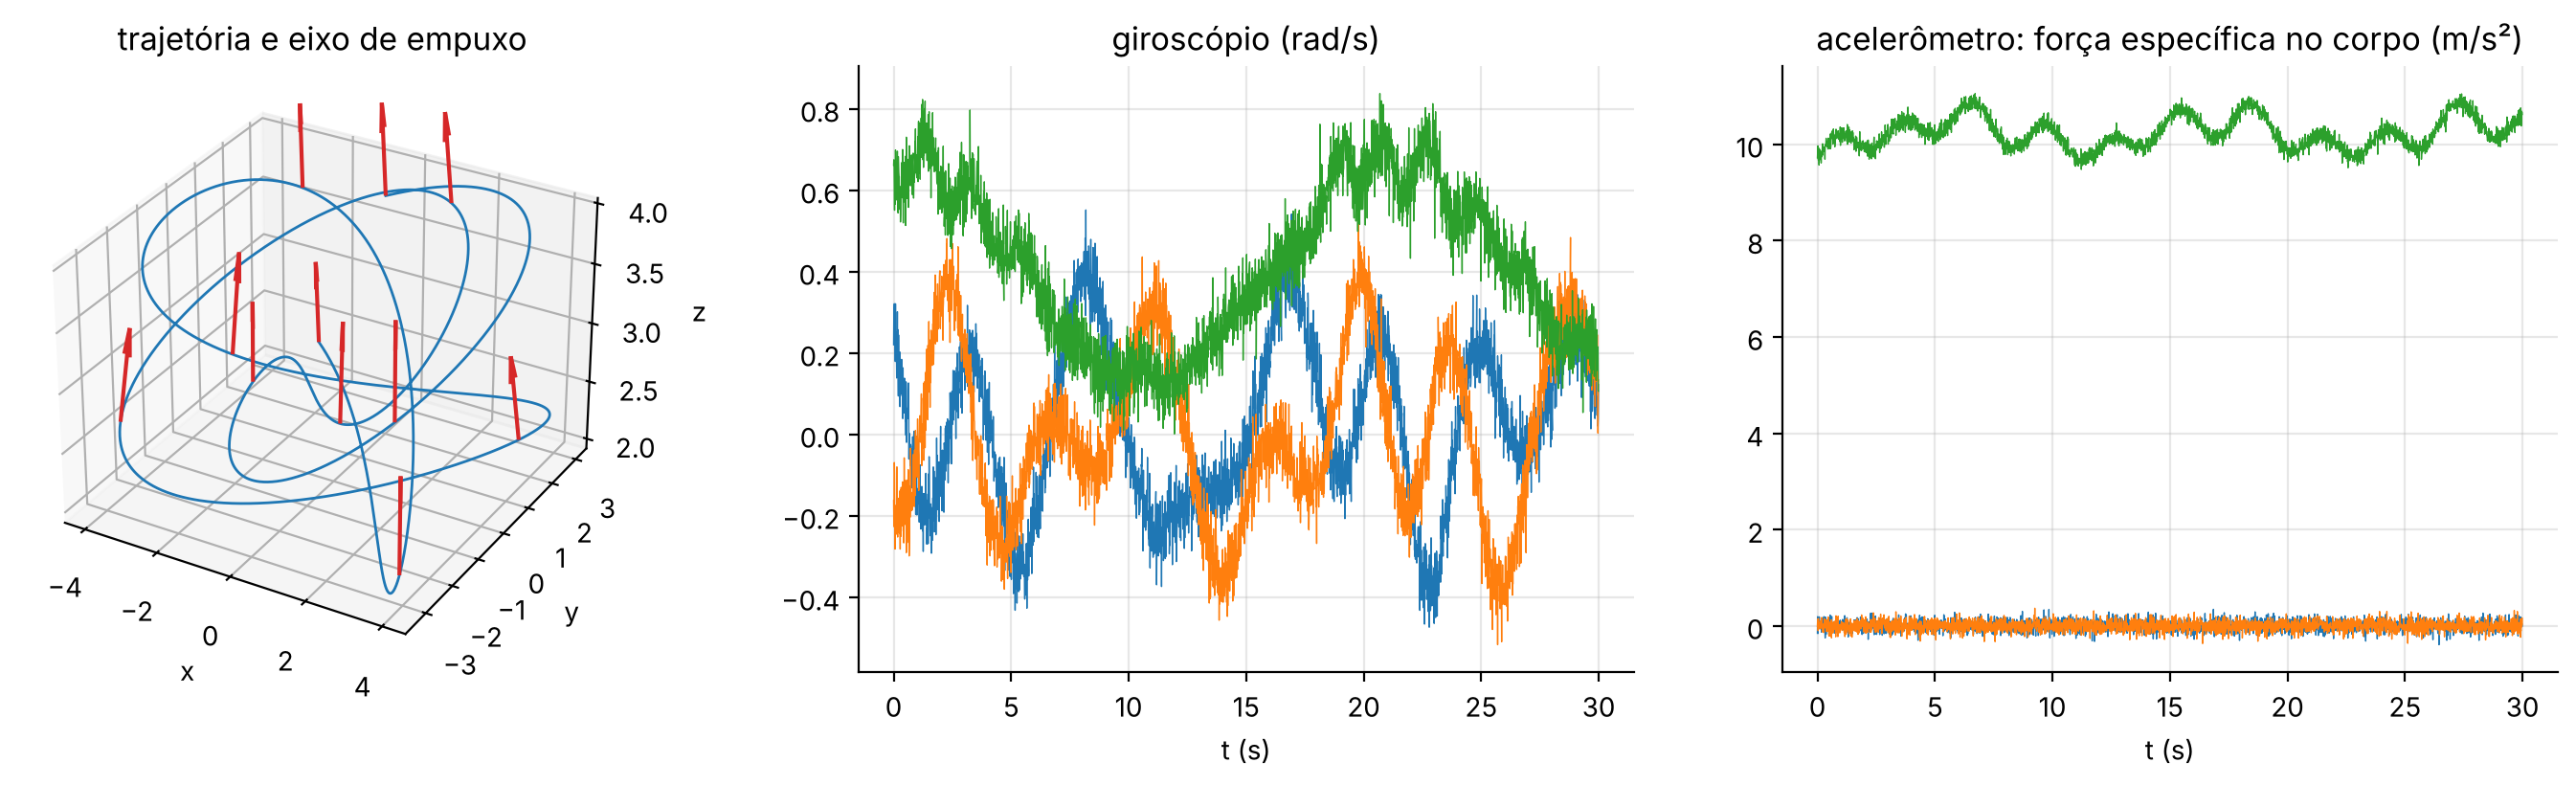

In [11]:
sim_demo = simula_voo(rng=np.random.default_rng(100))
P_v = np.array([x[2] for x in sim_demo["X"]])
fig = plt.figure(figsize=(14, 4.2))
ax = fig.add_subplot(1, 3, 1, projection="3d")
ax.plot(*P_v.T, lw=1)
for k in range(0, len(P_v), 300):                     # eixo z do corpo (direção do empuxo)
    z = sim_demo["X"][k][0][:, 2]; ax.quiver(*P_v[k], *z, length=0.8, color="tab:red")
ax.set_title("trajetória e eixo de empuxo"); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
ax2 = fig.add_subplot(1, 3, 2)
ax2.plot(sim_demo["ts"][:-1], sim_demo["w_m"], lw=.5); ax2.set_title("giroscópio (rad/s)"); ax2.set_xlabel("t (s)")
ax3 = fig.add_subplot(1, 3, 3)
ax3.plot(sim_demo["ts"][:-1], sim_demo["a_m"], lw=.5); ax3.set_title("acelerômetro: força específica no corpo (m/s²)")
ax3.set_xlabel("t (s)"); plt.tight_layout(); plt.show()

**Leitura.** É um voo tranquilo: rotações de até 0,8 rad/s e acelerações de até 1 m/s². O acelerômetro mede quase só o eixo $z$ do corpo, entre 9,7 e 10,9 m/s²: o quadrotor está sempre "pendurado" no próprio empuxo. É por isso que a guinada é difícil de estimar só com GPS: ela só aparece quando o drone **acelera de lado**, e o filtro compara para onde o acelerômetro diz que empurrou com para onde o GPS diz que o drone foi.

---
# 5. Um filtro, quatro $\boxplus$

O ESKF do notebook 5 tem três ingredientes que dependem da representação: a injeção da correção ($\boxplus$), a diferença entre estados ($\boxminus$) e os jacobianos ($\mathbf F$, do erro na propagação; $\mathbf G$, do ruído da IMU; $\mathbf H$, da medida). Todo o resto (predição da covariância, ganho, reset) é o **mesmo código**. Comparamos quatro escolhas de erro $\boldsymbol\delta\in\mathbb R^9$:

| filtro | estado nominal | como o erro $\boldsymbol\delta$ entra |
|---|---|---|
| **(a)** quaternion + vetores | $q,\ \mathbf v,\ \mathbf p$ | $\mathbf R=\hat{\mathbf R}\,\mathrm{Exp}(\delta\boldsymbol\theta)$, $\ \mathbf v=\hat{\mathbf v}+\delta\mathbf v$, $\ \mathbf p=\hat{\mathbf p}+\delta\mathbf p$ |
| **(b)** dual quaternion + velocidade (Filipe et al.) | $\hat q,\ \mathbf v$ | $\hat q=\hat{\hat q}\otimes\mathrm{Exp}(\delta\boldsymbol\theta,\boldsymbol\rho)$, $\ \mathbf v=\hat{\mathbf v}+\delta\mathbf v$ |
| **(c)** tridente, erro à esquerda (LQEKF) | $\tilde q$ | $\tilde q=\hat{\tilde q}\otimes\mathrm{Exp}(\delta\boldsymbol\theta,\boldsymbol\nu,\boldsymbol\rho)$: erro no **corpo** |
| **(d)** tridente, erro à direita (RQEKF) | $\tilde q$ | $\tilde q=\mathrm{Exp}(\delta\boldsymbol\theta,\boldsymbol\nu,\boldsymbol\rho)\otimes\hat{\tilde q}$: erro no **mundo** |

Os nomes LQEKF e RQEKF são de Ouyang e Wu (Parte II), que deduzem os dois modelos de erro do tridente e mostram que coincidem com os do filtro de Kalman invariante de Barrau e Bonnabel.

**Os jacobianos da propagação**, deduzidos à mão (com $\Gamma=\mathrm{Exp}(\boldsymbol\omega\Delta t)$, $\mathbf A=[\mathbf a]_\times$; linhas e colunas na ordem $(\delta\boldsymbol\theta,\text{vel.},\text{pos.})$):

$$\mathbf F_{(a)}=\begin{bmatrix}\Gamma^\top&0&0\\-\hat{\mathbf R}\mathbf A\Delta t&\mathbf I&0\\-\tfrac12\hat{\mathbf R}\mathbf A\Delta t^2&\mathbf I\Delta t&\mathbf I\end{bmatrix},\qquad \mathbf F_{(c)}=\begin{bmatrix}\Gamma^\top&0&0\\-\Gamma^\top\mathbf A\Delta t&\Gamma^\top&0\\-\tfrac12\Gamma^\top\mathbf A\Delta t^2&\Gamma^\top\Delta t&\Gamma^\top\end{bmatrix},\qquad \mathbf F_{(d)}=\mathrm{Ad}_\Gamma\begin{bmatrix}\mathbf I&0&0\\0&\mathbf I&0\\0&\mathbf I\Delta t&\mathbf I\end{bmatrix}.$$

**Repare no que cada um depende:**
- $\mathbf F_{(a)}$ (e o de (b), no código) contém $\hat{\mathbf R}$, **a atitude estimada**. Se a estimativa está errada, a propagação da covariância também está.
- $\mathbf F_{(c)}$ só contém a IMU: **nenhuma** grandeza estimada.
- $\mathbf F_{(d)}$ é **constante**: só depende da gravidade e de $\Delta t$. O estado estimado aparece só no ruído, $\mathbf G_{(d)}=\mathrm{Ad}_{\hat{\tilde q}}\mathbf G_{(c)}$.

O código abaixo implementa as quatro classes. A primeira célula de conferência compara **todos** os jacobianos analíticos com derivadas numéricas feitas **na própria álgebra** (perturbando com $\boxplus$ e medindo com $\boxminus$).

In [12]:
# ---------------- os quatro grupos ----------------
class GrupoSO3xR6:
    """(a) quaternion + velocidade + posição: erro de atitude multiplicativo, v e p aditivos (no mundo)."""
    nome = "SO(3)×R⁶ (quaternion + vetores)"
    def de_Rvp(self, R, v, p): return (qfrommat(R), v.copy(), p.copy())
    def para_Rvp(self, X): return qmat(X[0]), X[1], X[2]
    def boxplus(self, X, d): return (qmul(X[0], qExp(d[:3])), X[1] + d[3:6], X[2] + d[6:])
    def boxminus(self, X1, X2): return np.concatenate([qLog(qmul(qconj(X2[0]), X1[0])), X1[1] - X2[1], X1[2] - X2[2]])
    def F_G(self, X, w_m, a_m, dt):
        R = qmat(X[0]); Gm = Exp3(w_m * dt); A = hat(a_m); I = np.eye(3); Z = np.zeros((3, 3))
        F = np.block([[Gm.T, Z, Z], [-R @ A * dt, I, Z], [-0.5 * R @ A * dt**2, I * dt, I]])
        Gn = np.block([[-Jr(w_m * dt) * dt, Z], [Z, -R * dt], [Z, -0.5 * R * dt**2]])
        return F, Gn
    def H_pos(self, X): return np.hstack([np.zeros((3, 6)), np.eye(3)])
    def ad(self, d):
        M = np.zeros((9, 9)); M[:3, :3] = hat(d[:3]); return M

class GrupoSE3xR3:
    """(b) dual quaternion (pose) + velocidade: erro de pose no grupo SE(3), velocidade aditiva no mundo."""
    nome = "SE(3)×R³ (dual quaternion + velocidade)"
    def de_Rvp(self, R, v, p): return (dq(qfrommat(R), p), v.copy())
    def para_Rvp(self, X): r, p = dq_parts(X[0]); return qmat(r), X[1], p
    def boxplus(self, X, d):   # ordem do erro: (theta, v, rho)
        return (dqmul(X[0], dqExp(np.concatenate([d[:3], d[6:]]))), X[1] + d[3:6])
    def boxminus(self, X1, X2):
        xi = dqLog(dqmul(dqconj(X2[0]), X1[0]))
        return np.concatenate([xi[:3], X1[1] - X2[1], xi[3:]])
    def F_G(self, X, w_m, a_m, dt):
        R = self.para_Rvp(X)[0]; Gm = Exp3(w_m * dt); A = hat(a_m); I = np.eye(3); Z = np.zeros((3, 3))
        F = np.block([[Gm.T, Z, Z], [-R @ A * dt, I, Z], [-0.5 * Gm.T @ A * dt**2, Gm.T @ R.T * dt, Gm.T]])
        Gn = np.block([[-Jr(w_m * dt) * dt, Z], [Z, -R * dt], [Z, -0.5 * Gm.T * dt**2]])
        return F, Gn
    def H_pos(self, X): return np.hstack([np.zeros((3, 6)), self.para_Rvp(X)[0]])
    def ad(self, d):
        M = np.zeros((9, 9)); th, rho = d[:3], d[6:]
        M[:3, :3] = hat(th); M[6:, :3] = hat(rho); M[6:, 6:] = hat(th); return M

class GrupoSE23:
    """(c) quaternion tridente, erro à esquerda (no corpo): X = X̂ ⊗ Exp(δ)  (LQEKF de Ouyang e Wu)."""
    nome = "SE₂(3) tridente, erro à esquerda (LQEKF)"
    def de_Rvp(self, R, v, p): return tq(qfrommat(R), v, p)
    def para_Rvp(self, X): r, v, p = tq_parts(X); return qmat(r), v, p
    def boxplus(self, X, d): return tqmul(X, tqExp(d))
    def boxminus(self, X1, X2): return tqLog(tqmul(tqconj(X2), X1))
    def F_G(self, X, w_m, a_m, dt):
        # repare: nenhum termo depende do estado estimado X — só da IMU
        Gm = Exp3(w_m * dt); A = hat(a_m); Z = np.zeros((3, 3))
        F = np.block([[Gm.T, Z, Z], [-Gm.T @ A * dt, Gm.T, Z], [-0.5 * Gm.T @ A * dt**2, Gm.T * dt, Gm.T]])
        Gn = np.block([[-Jr(w_m * dt) * dt, Z], [Z, -Gm.T * dt], [Z, -0.5 * Gm.T * dt**2]])
        return F, Gn
    def H_pos(self, X): return np.hstack([np.zeros((3, 6)), self.para_Rvp(X)[0]])
    def ad(self, d):
        M = np.zeros((9, 9)); th, nu, rho = d[:3], d[3:6], d[6:]
        M[:3, :3] = hat(th); M[3:6, :3] = hat(nu); M[3:6, 3:6] = hat(th); M[6:, :3] = hat(rho); M[6:, 6:] = hat(th)
        return M

def propaga_grupo(g, X, w_m, a_m, dt):
    return g.de_Rvp(*propaga_fisica(*g.para_Rvp(X), w_m, a_m, dt))

In [13]:
def Ad23(R, v, p):
    Z = np.zeros((3, 3))
    return np.block([[R, Z, Z], [hat(v) @ R, R, Z], [hat(p) @ R, Z, R]])

class GrupoSE23Dir(GrupoSE23):
    """(d) tridente com erro à DIREITA (no referencial do mundo): X = Exp(δ) ⊗ X̂  (RQEKF de Ouyang e Wu)."""
    nome = "SE₂(3) tridente, erro à direita (RQEKF)"
    def boxplus(self, X, d): return tqmul(tqExp(d), X)
    def boxminus(self, X1, X2): return tqLog(tqmul(X1, tqconj(X2)))
    def F_G(self, X, w_m, a_m, dt):
        # F não depende nem do estado nem da IMU: só da gravidade e de dt
        I = np.eye(3); Z = np.zeros((3, 3))
        MPhi = np.block([[I, Z, Z], [Z, I, Z], [Z, I * dt, I]])
        F = Ad23(I, G_VEC * dt, 0.5 * G_VEC * dt**2) @ MPhi
        _, Gl = GrupoSE23.F_G(self, X, w_m, a_m, dt)
        Xn = self.para_Rvp(propaga_grupo(self, X, w_m, a_m, dt))
        return F, Ad23(*Xn) @ Gl                    # o ruído entra "girado" pelo estado
    def H_att(self, X): return np.hstack([self.para_Rvp(X)[0].T, np.zeros((3, 6))])
    def H_pos(self, X):
        p = self.para_Rvp(X)[2]; return np.hstack([-hat(p), np.zeros((3, 3)), np.eye(3)])
    def ad(self, d): return -GrupoSE23.ad(self, d)  # o reset à direita tem o sinal trocado: G ≈ I + ½ ad

In [14]:
# ---------------- o filtro (o mesmo código para os três grupos) ----------------
def H_e_residuo(g, X, z, tipo):
    """tipo 'pose': z = (R_med, p_med); tipo 'pos': z = p_med. Resíduo no espaço da medida."""
    R, v, p = g.para_Rvp(X)
    if tipo == "pose":
        Ha = g.H_att(X) if hasattr(g, "H_att") else np.hstack([np.eye(3), np.zeros((3, 6))])
        H = np.vstack([Ha, g.H_pos(X)])
        r = np.concatenate([Log3(R.T @ z[0]), z[1] - p])
    else:
        H = g.H_pos(X); r = z - p
    return H, r

def eskf(g, sim, med, x0, P0, sig_g, sig_a, Rmed, tipo, usa_reset=True):
    """med: dicionário {índice do passo: medida}. x0 = (R, v, p) inicial estimado."""
    X = g.de_Rvp(*x0); P = P0.copy(); Qn = np.diag([sig_g**2] * 3 + [sig_a**2] * 3)
    est, covs = [X], [P.copy()]
    for k in range(len(sim["w_m"])):
        F, Gn = g.F_G(X, sim["w_m"][k], sim["a_m"][k], sim["dt"])
        X = propaga_grupo(g, X, sim["w_m"][k], sim["a_m"][k], sim["dt"])
        P = F @ P @ F.T + Gn @ Qn @ Gn.T
        if k + 1 in med:
            H, r = H_e_residuo(g, X, med[k + 1], tipo)
            S = H @ P @ H.T + Rmed
            K = np.linalg.solve(S, H @ P).T
            d = K @ r
            X = g.boxplus(X, d)
            P = (np.eye(9) - K @ H) @ P
            if usa_reset:
                Gr = np.eye(9) - 0.5 * g.ad(d); P = Gr @ P @ Gr.T
            P = 0.5 * (P + P.T)
        est.append(X); covs.append(P.copy())
    return est, np.array(covs)

In [15]:
GRUPOS = [GrupoSO3xR6(), GrupoSE3xR3(), GrupoSE23(), GrupoSE23Dir()]
X0 = (Exp3(rng.normal(size=3)), rng.normal(size=3), rng.normal(size=3))
w_t, a_t, dt = rng.normal(size=3), rng.normal(size=3) + [0, 0, 9.8], 0.01
for g in GRUPOS:
    X = g.de_Rvp(*X0); F, Gn = g.F_G(X, w_t, a_t, dt)
    Fn = jacobiano_numerico(lambda d: g.boxminus(propaga_grupo(g, g.boxplus(X, d), w_t, a_t, dt), propaga_grupo(g, X, w_t, a_t, dt)), np.zeros(9))
    Gnn = jacobiano_numerico(lambda n: g.boxminus(propaga_grupo(g, X, w_t - n[:3], a_t - n[3:], dt), propaga_grupo(g, X, w_t, a_t, dt)), np.zeros(6))
    Hn = jacobiano_numerico(lambda d: g.para_Rvp(g.boxplus(X, d))[2], np.zeros(9))
    print(g.nome)
    confere("   F analítico = numérico", F, Fn, tol=1e-8)
    confere("   G (ruído da IMU) analítico = numérico", Gn, Gnn, tol=1e-8)
    confere("   H (posição) analítico = numérico", g.H_pos(X), Hn, tol=1e-8)

SO(3)×R⁶ (quaternion + vetores)
OK      F analítico = numérico:  diferença máxima = 2.57e-10
OK      G (ruído da IMU) analítico = numérico:  diferença máxima = 2.46e-10
OK      H (posição) analítico = numérico:  diferença máxima = 1.40e-10
SE(3)×R³ (dual quaternion + velocidade)
OK      F analítico = numérico:  diferença máxima = 2.66e-10
OK      G (ruído da IMU) analítico = numérico:  diferença máxima = 2.46e-10
OK      H (posição) analítico = numérico:  diferença máxima = 1.11e-10
SE₂(3) tridente, erro à esquerda (LQEKF)
OK      F analítico = numérico:  diferença máxima = 4.08e-10
OK      G (ruído da IMU) analítico = numérico:  diferença máxima = 2.46e-10
OK      H (posição) analítico = numérico:  diferença máxima = 1.11e-10
SE₂(3) tridente, erro à direita (RQEKF)
OK      F analítico = numérico:  diferença máxima = 6.11e-10
OK      G (ruído da IMU) analítico = numérico:  diferença máxima = 3.80e-10
OK      H (posição) analítico = numérico:  diferença máxima = 1.93e-10


In [16]:
# quem depende de quê: o mesmo passo de IMU, duas estimativas bem diferentes
Xa = (Exp3(np.array([0.1, -0.2, 0.3])), np.array([1.0, 0, 0]), np.array([0.0, 2, 3]))
Xb = (Exp3(np.array([0.5, 0.4, 2.8])), np.array([-3.0, 1, 0]), np.array([10.0, -4, 1]))
linhas = []
for g in GRUPOS:
    Fa, _ = g.F_G(g.de_Rvp(*Xa), w_t, a_t, dt)
    Fb, _ = g.F_G(g.de_Rvp(*Xb), w_t, a_t, dt)
    Fc, _ = g.F_G(g.de_Rvp(*Xa), -w_t, 2 * a_t, dt)
    linhas.append({"filtro": g.nome,
                   "muda F trocar a ESTIMATIVA?": f"{np.abs(Fa - Fb).max():.1e}",
                   "muda F trocar a IMU?": f"{np.abs(Fa - Fc).max():.1e}"})
pd.DataFrame(linhas).set_index("filtro")

,muda F trocar a ESTIMATIVA?,muda F trocar a IMU?
filtro,,
SO(3)×R⁶ (quaternion + vetores),1.9e-01,9.3e-02
SE(3)×R³ (dual quaternion + velocidade),1.9e-01,9.3e-02
"SE₂(3) tridente, erro à esquerda (LQEKF)",0.0e+00,9.7e-02
"SE₂(3) tridente, erro à direita (RQEKF)",0.0e+00,0.0e+00


**Leitura.** Só os dois filtros tridentes têm um $\mathbf F$ que **não depende da estimativa**. No (d), ele não depende nem da IMU. Guardemos isso para o experimento 2.

**O reset.** Depois de injetar a correção $\boldsymbol\delta$, a covariância é corrigida por $\mathbf G\approx\mathbf I-\tfrac12\,\mathrm{ad}_{\boldsymbol\delta}$ (erro à esquerda) ou $\mathbf I+\tfrac12\,\mathrm{ad}_{\boldsymbol\delta}$ (erro à direita), em que $\mathrm{ad}$ é a matriz adjunta da álgebra de Lie de cada grupo. Para (a), só o bloco da atitude; para (c) e (d), o bloco $9\times9$ inteiro. É a mesma aproximação de primeira ordem do notebook 5.

---
# 6. Experimento 1: medidas de pose a 10 Hz e a 0,5 Hz

**A pergunta de Filipe et al.** No artigo do DQ-MEKF, o filtro com dual quaternion empata em atitude com as alternativas, mas **ganha em posição quando as medidas de pose são raras** (0,5 Hz). Repetimos a pergunta no quadrotor: uma câmera ou um sistema de captura de movimento mede a pose ($\sigma=1°$ e 5 cm), a 10 Hz ou a 0,5 Hz, e o filtro começa com erros **pequenos** (3° em rolagem e arfagem, 10° em guinada, 0,3 m/s, 0,5 m).

> **Atenção à covariância inicial do filtro (d).** No erro à direita, uma incerteza de guinada também move a posição, por $-\hat{\mathbf p}\times\delta\boldsymbol\theta$: girar o mundo em torno da origem arrasta o drone junto. Uma $\mathbf P_0$ diagonal escrita "no corpo" é, portanto, **inconsistente** para (d). A correspondência exata é $\hat{\tilde q}\otimes\mathrm{Exp}(\boldsymbol\delta)=\mathrm{Exp}(\mathrm{Ad}_{\hat{\tilde q}}\boldsymbol\delta)\otimes\hat{\tilde q}$, e por isso a função abaixo usa $\mathbf P_0^{(d)}=\mathrm{Ad}\,\mathbf P_0\,\mathrm{Ad}^\top$. O experimento 2 mostra o que acontece quando se esquece disso.

In [17]:
def P0_para(g, P0, x0, ingenua=False):
    if isinstance(g, GrupoSE23Dir) and not ingenua:
        A = Ad23(*x0); return A @ P0 @ A.T
    return P0

def metricas(g, sim, est, P):
    n = len(est)
    e_att = np.array([np.degrees(np.linalg.norm(Log3(sim["X"][k][0].T @ g.para_Rvp(est[k])[0]))) for k in range(n)])
    e_pos = np.array([np.linalg.norm(sim["X"][k][2] - g.para_Rvp(est[k])[2]) for k in range(n)])
    e_vel = np.array([np.linalg.norm(sim["X"][k][1] - g.para_Rvp(est[k])[1]) for k in range(n)])
    nees = np.array([(lambda e: e @ np.linalg.solve(P[k], e))(g.boxminus(g.de_Rvp(*sim["X"][k]), est[k])) for k in range(n)])
    return e_att, e_pos, e_vel, nees

def experimento_pose(hz, n_mc=N_MC):
    linhas = {g.nome: [] for g in GRUPOS}
    for run in range(n_mc):
        rng_r = np.random.default_rng(100 + run); sim = simula_voo(rng=rng_r)
        passo = int(round(1 / hz / sim["dt"])); R, v, p = sim["X"][0]
        med = {k: (sim["X"][k][0] @ Exp3(np.radians(1) * rng_r.normal(size=3)), sim["X"][k][2] + 0.05 * rng_r.normal(size=3))
               for k in range(passo, len(sim["X"]), passo)}
        d0 = np.r_[np.radians([3, 3, 10]) * rng_r.normal(size=3), 0.3 * rng_r.normal(size=3), 0.5 * rng_r.normal(size=3)]
        x0 = (R @ Exp3(d0[:3]), v + d0[3:6], p + d0[6:])
        P0 = np.diag([np.radians(3)**2] * 2 + [np.radians(10)**2] + [0.3**2] * 3 + [0.5**2] * 3)
        Rmed = np.diag([np.radians(1)**2] * 3 + [0.05**2] * 3)
        for g in GRUPOS:
            est, P = eskf(g, sim, med, x0, P0_para(g, P0, x0), 0.05, 0.1, Rmed, "pose")
            ea, ep, ev, ne = metricas(g, sim, est, P)
            linhas[g.nome].append([ea[500:].mean(), 100 * ep[500:].mean(), 100 * ev[500:].mean(), ne[500:].mean()])
    return pd.DataFrame({k: np.mean(v, 0) for k, v in linhas.items()},
                        index=["atitude (°)", "posição (cm)", "velocidade (cm/s)", "NEES (ideal 9)"]).T

tab_pose = pd.concat({"pose a 10 Hz": experimento_pose(10), "pose a 0,5 Hz": experimento_pose(0.5)}, axis=1)
tab_pose.round(3)

pose a 10 Hz               \
                                          atitude (°) posição (cm)   
SO(3)×R⁶ (quaternion + vetores)                 0.446        3.443   
SE(3)×R³ (dual quaternion + velocidade)         0.446        3.443   
SE₂(3) tridente, erro à esquerda (LQEKF)        0.446        3.442   
SE₂(3) tridente, erro à direita (RQEKF)         0.446        3.442   

                                                                           \
                                         velocidade (cm/s) NEES (ideal 9)   
SO(3)×R⁶ (quaternion + vetores)                      4.962          9.099   
SE(3)×R³ (dual quaternion + velocidade)              4.962          9.106   
SE₂(3) tridente, erro à esquerda (LQEKF)             4.960          9.091   
SE₂(3) tridente, erro à direita (RQEKF)              4.960          9.091   

                                         pose a 0,5 Hz               \
                                           atitude (°) posição (cm)   
SO(3)×R⁶ (quaternion + vetores)                  0.834       18.815   
SE(3)×R³ (dual quaternion + velocidade)          0.836       18.999   
SE₂(3) tridente, erro à esquerda (LQEKF)         0.837       19.106   
SE₂(3) tridente, erro à direita (RQEKF)          0.837       19.106   

                                                                           
                                         velocidade (cm/s) NEES (ideal 9)  
SO(3)×R⁶ (quaternion + vetores)                     17.493          8.616  
SE(3)×R³ (dual quaternion + velocidade)             17.717          8.825  
SE₂(3) tridente, erro à esquerda (LQEKF)            17.787          8.803  
SE₂(3) tridente, erro à direita (RQEKF)             17.787          8.803

**Leitura.** Com erros iniciais pequenos, **as quatro escolhas dão praticamente os mesmos números**. A 10 Hz, são iguais até a segunda casa; a 0,5 Hz, diferem em 1% a 2%, e, se alguém ganha, é o quaternion + vetores. Todas são consistentes (NEES perto de 9). A vantagem do dual quaternion a 0,5 Hz relatada por Filipe et al. **não se reproduz aqui**. Lá, o filtro não usava acelerômetro na versão principal (a velocidade era medida, não integrada) e a medida de pose estava num referencial diferente do estado; aqui, a IMU completa domina entre medidas, e a propagação da IMU é idêntica nos quatro filtros.

Isso não é decepcionante, é esperado: quando o erro é pequeno, $\boxplus$ é quase uma soma em qualquer representação, e todas as linearizações coincidem em primeira ordem. As diferenças só podem aparecer quando o erro é **grande**.

---
# 7. Experimento 2: só GPS, com a guinada errada

Agora o cenário difícil, e o mais comum na prática: o drone liga sem saber para onde aponta (sem magnetômetro, ou com o magnetômetro perturbado pelos motores) e só tem **GPS** (posição, 2 Hz, $\sigma=0{,}5$ m). Rolagem e arfagem saem logo da gravidade, mas a **guinada** só aparece aos poucos, nas acelerações laterais. Variamos o erro inicial de guinada de 10° a 150°, com a covariância inicial honesta ($\sigma_\psi$ igual ao erro).

É o equivalente aéreo do "alinhamento em movimento" da Parte II de Ouyang e Wu, que relatam que os filtros tridentes convergem mesmo com guinada inicial arbitrária, onde o EKF tradicional diverge. O experimento inclui também o filtro (d) com a $\mathbf P_0$ **ingênua**.

In [18]:
def experimento_gps(psi0_graus, n_mc=N_MC):
    variantes = [(g, False) for g in GRUPOS] + [(GRUPOS[3], True)]
    linhas = {}
    for run in range(n_mc):
        rng_r = np.random.default_rng(500 + run); sim = simula_voo(rng=rng_r); R, v, p = sim["X"][0]
        med = {k: sim["X"][k][2] + 0.5 * rng_r.normal(size=3) for k in range(50, len(sim["X"]), 50)}
        sinal = rng_r.choice([-1, 1])
        x0 = (R @ Exp3(np.r_[np.radians(2) * rng_r.normal(size=2), sinal * np.radians(psi0_graus)]),
              v + 0.3 * rng_r.normal(size=3), p + 0.5 * rng_r.normal(size=3))
        P0 = np.diag([np.radians(3)**2] * 2 + [np.radians(psi0_graus)**2] + [0.3**2] * 3 + [0.5**2] * 3)
        for g, ingenua in variantes:
            nome = g.nome + (" com P₀ ingênua" if ingenua else "")
            est, P = eskf(g, sim, med, x0, P0_para(g, P0, x0, ingenua), 0.05, 0.1, 0.5**2 * np.eye(3), "pos")
            ea, ep, ev, ne = metricas(g, sim, est, P)
            linhas.setdefault(nome, []).append(dict(e10=ea[1000], e30=ea[-1], pos=ep[1000:].mean(),
                                                     nees_ini=ne[100:1000].mean(), nees=ne[1000:].mean(), conv=ea[-1] < 5))
            if run == 0:
                CURVAS.setdefault(psi0_graus, {})[nome] = ea
    out = {}
    for nome, L in linhas.items():
        d = pd.DataFrame(L)
        out[nome] = {"erro de atitude em 10 s (°, mediana)": d.e10.median(), "erro em 30 s (°, mediana)": d.e30.median(),
                     "posição após 10 s (m, mediana)": d.pos.median(), "NEES 1–10 s (mediana)": d.nees_ini.median(),
                     "NEES 10–30 s (mediana)": d.nees.median(), "convergiu (< 5° em 30 s)": f"{d.conv.sum()}/{len(d)}"}
    return pd.DataFrame(out).T

CURVAS = {}
tabs = {f"{psi}°": experimento_gps(psi) for psi in [10, 45, 90, 120, 150]}
tab_gps = pd.concat(tabs, names=["guinada inicial", "filtro"])
tab_gps.round(2)

erro de atitude em 10 s (°, mediana)  \
guinada inicial filtro                                                                                    
10°             SO(3)×R⁶ (quaternion + vetores)                                                1.355727   
                SE(3)×R³ (dual quaternion + velocidade)                                        1.562132   
                SE₂(3) tridente, erro à esquerda (LQEKF)                                       1.150369   
                SE₂(3) tridente, erro à direita (RQEKF)                                        1.150339   
                SE₂(3) tridente, erro à direita (RQEKF) com P₀ ...                             1.361396   
45°             SO(3)×R⁶ (quaternion + vetores)                                                1.578902   
                SE(3)×R³ (dual quaternion + velocidade)                                        1.850335   
                SE₂(3) tridente, erro à esquerda (LQEKF)                                       0.948081   
                SE₂(3) tridente, erro à direita (RQEKF)                                         0.94843   
                SE₂(3) tridente, erro à direita (RQEKF) com P₀ ...                              2.04816   
90°             SO(3)×R⁶ (quaternion + vetores)                                                3.054671   
                SE(3)×R³ (dual quaternion + velocidade)                                        1.493668   
                SE₂(3) tridente, erro à esquerda (LQEKF)                                       2.241746   
                SE₂(3) tridente, erro à direita (RQEKF)                                        2.220177   
                SE₂(3) tridente, erro à direita (RQEKF) com P₀ ...                              57.1029   
120°            SO(3)×R⁶ (quaternion + vetores)                                                5.036655   
                SE(3)×R³ (dual quaternion + velocidade)                                        5.510283   
                SE₂(3) tridente, erro à esquerda (LQEKF)                                       2.257399   
                SE₂(3) tridente, erro à direita (RQEKF)                                        2.361957   
                SE₂(3) tridente, erro à direita (RQEKF) com P₀ ...                            46.214054   
150°            SO(3)×R⁶ (quaternion + vetores)                                               37.775483   
                SE(3)×R³ (dual quaternion + velocidade)                                       15.270809   
                SE₂(3) tridente, erro à esquerda (LQEKF)                                       3.840888   
                SE₂(3) tridente, erro à direita (RQEKF)                                         4.01347   
                SE₂(3) tridente, erro à direita (RQEKF) com P₀ ...                            39.379047   

                                                                   erro em 30 s (°, mediana)  \
guinada inicial filtro                                                                         
10°             SO(3)×R⁶ (quaternion + vetores)                                     1.139159   
                SE(3)×R³ (dual quaternion + velocidade)                             1.127251   
                SE₂(3) tridente, erro à esquerda (LQEKF)                            1.117565   
                SE₂(3) tridente, erro à direita (RQEKF)                             1.117586   
                SE₂(3) tridente, erro à direita (RQEKF) com P₀ ...                  1.214993   
45°             SO(3)×R⁶ (quaternion + vetores)                                     1.166403   
                SE(3)×R³ (dual quaternion + velocidade)                             1.226507   
                SE₂(3) tridente, erro à esquerda (LQEKF)                            1.139237   
                SE₂(3) tridente, erro à direita (RQEKF)                             1.139284   
                SE₂(3) tridente, erro à direita (RQEKF) com P₀ ...                  1.222492   
90°             SO(3)×R⁶ 

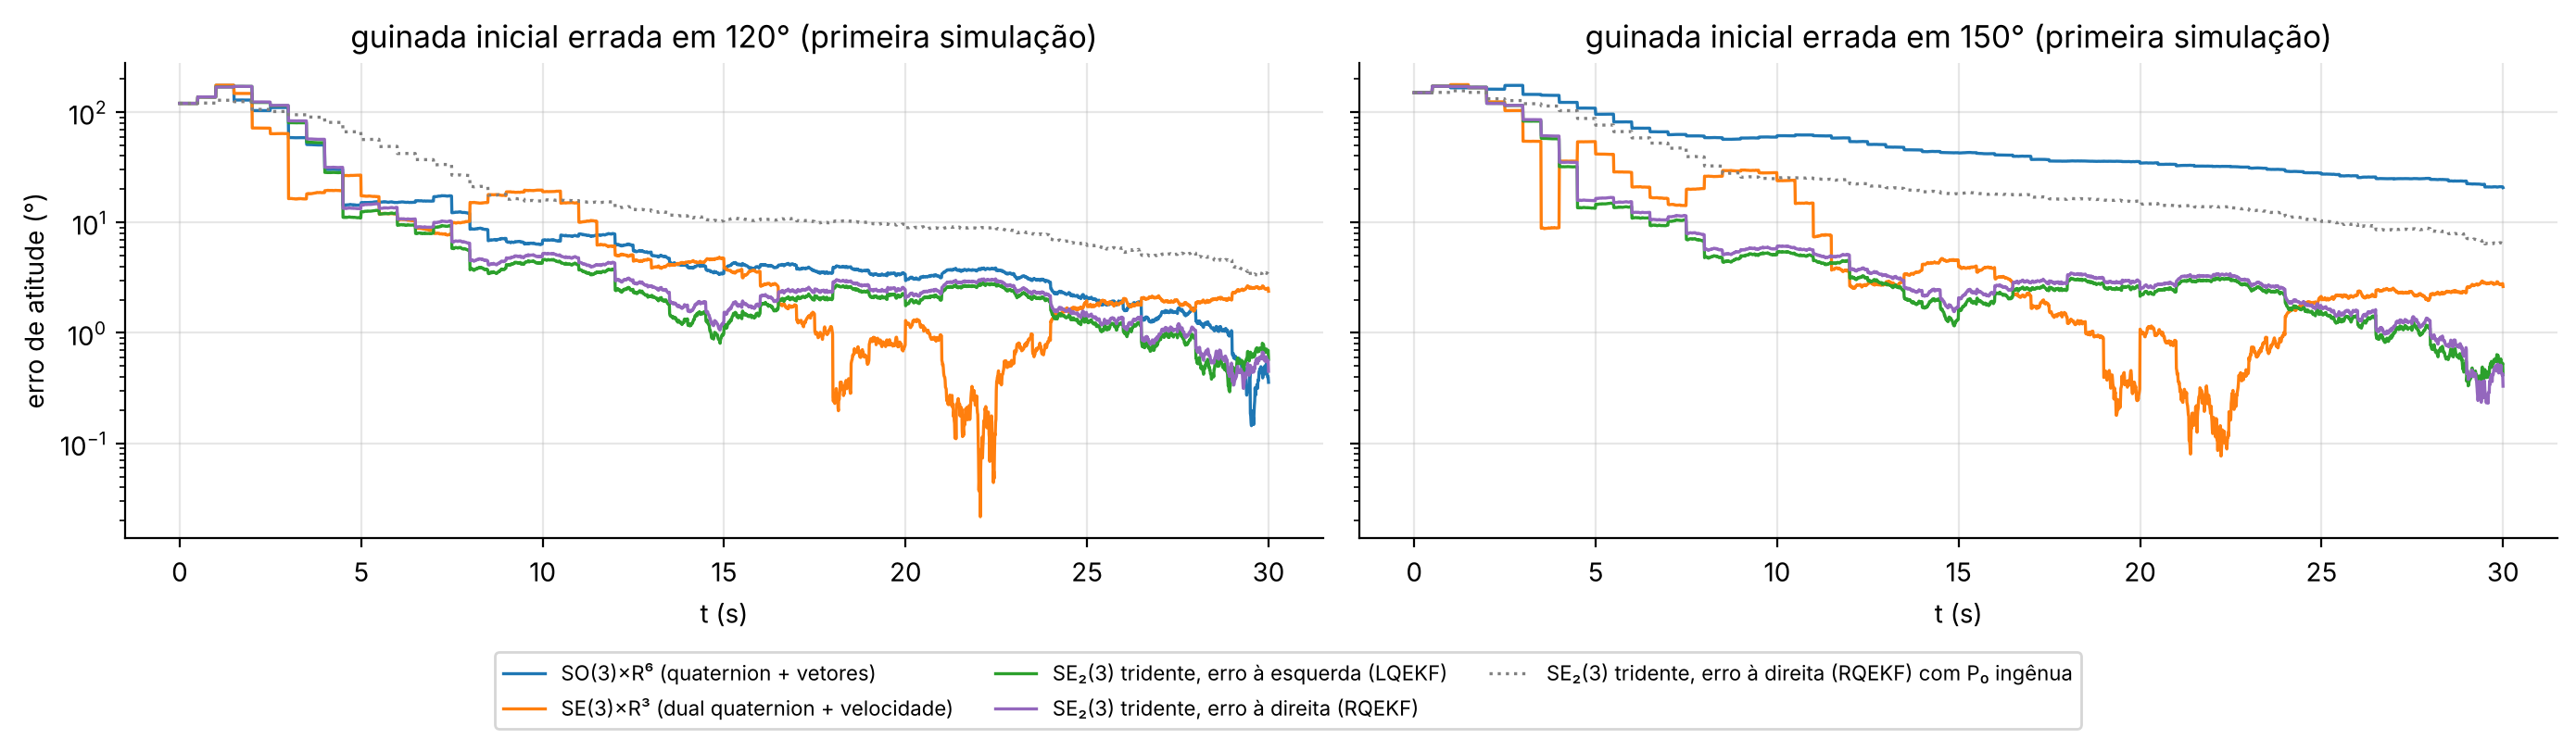

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
t = np.arange(len(next(iter(CURVAS[150].values())))) * 0.01
estilos = {GRUPOS[0].nome: "tab:blue", GRUPOS[1].nome: "tab:orange", GRUPOS[2].nome: "tab:green", GRUPOS[3].nome: "tab:purple"}
for ax, psi in zip(axs, [120, 150]):
    for nome, curva in CURVAS[psi].items():
        ingen = "ingênua" in nome
        ax.semilogy(t, np.maximum(curva, 1e-2), lw=1.2, ls=":" if ingen else "-",
                    color="gray" if ingen else estilos[nome], label=nome)
    ax.set_title(f"guinada inicial errada em {psi}° (primeira simulação)"); ax.set_xlabel("t (s)")
axs[0].set_ylabel("erro de atitude (°)")
h, l = axs[0].get_legend_handles_labels(); fig.legend(h, l, loc="lower center", ncol=3, fontsize=8)
plt.tight_layout(rect=(0, 0.1, 1, 1)); plt.show()

**Leitura.**
- **Até 120°, todos acabam convergindo** em 30 s: num voo com acelerações laterais, o GPS acaba ensinando a guinada a qualquer um dos filtros.
- **Mas só os tridentes são honestos no caminho.** Com 45° de erro, o NEES mediano de (a) e (b) no primeiro trecho já é 16 a 18 (ideal 9); com 90°, 60; com 120°, 150 a 390. Os tridentes ficam entre 8 e 12. Um filtro que se declara certo enquanto está 10° errado é perigoso: um controlador, ou um teste de falhas do $\chi^2$, confia nele.
- **A 150°**, a diferença vira convergência: (a) converge em 5 de 12 simulações e tem erro mediano de 38° aos 10 s; os dois tridentes convergem em 11 e 12 de 12, com cerca de 4° aos 10 s e 1° aos 30 s.
- **O dual quaternion ajuda, mas pela metade.** A versão (b) acopla rotação e posição e converge em 10 de 12 a 150°, bem melhor que (a). Mas continua tão otimista quanto (a) (NEES de 1.200 no início e 100 depois de 10 s), porque a **velocidade** ainda é um vetor solto, com erro "no mundo". O acelerômetro integra a velocidade **girada pela atitude estimada**, e um erro de guinada contamina a velocidade de um jeito que o modelo linearizado de (b) não descreve. O tridente, que põe a velocidade **dentro** do grupo, resolve.
- **Esquerda e direita dão o mesmo resultado**, como dizem Ouyang e Wu, **desde que a $\mathbf P_0$ esteja no referencial do erro**. Com a $\mathbf P_0$ ingênua, o filtro (d) é o pior de todos a partir de 90° (5, 4 e 0 convergências em 12): o mesmo algoritmo, com uma covariância inicial que descreve outra incerteza.

**Por quê?** No erro à esquerda (c), a equação linearizada do erro não depende da estimativa (seção 5). A covariância propagada é, portanto, a **certa** mesmo quando a estimativa está muito errada: a linearização não se contamina com o próprio erro que deveria descrever. Em (a) e (b), $\mathbf F$ contém $\hat{\mathbf R}$; com a guinada errada em 150°, o filtro propaga uma covariância correta para **outro** drone, se acha certo e para de ouvir o GPS. É a mesma doença do EKF "confiante demais" do notebook 3 (Pepé), agora com um remédio estrutural.

---
# 8. O quaternion dentro do estado (Jeon et al., 2022)

Jeon et al. estimam a atitude (e o deslocamento) de uma estrutura fundindo IMU, magnetômetro e câmera com um **IEKF em que o quaternion inteiro é o estado**: quatro componentes, corrigidas por **soma**, com uma covariância $4\times4$. É a abordagem do "EKF ingênuo", o contrário do ESKF. Dois pontos a favor e um contra:
- **a favor:** o passo iterado está na forma **correta** de Bell e Cathey (a soma é feita à predição, $\hat{\mathbf x}^{i+1}=\hat{\mathbf x}_{k|k-1}+\mathbf K^i(\cdot)$), ao contrário da forma impressa nas notas de Im (notebook 5, seção 6);
- **a favor:** em atitude, com erros moderados, o EKF ingênuo funciona;
- **contra:** a covariância $4\times4$ tem uma direção sem significado físico, a **radial** ($\|q\|$), que nenhuma medida informa. No texto extraído do artigo não encontrei como eles tratam a norma depois da correção.

A célula abaixo compara, no problema de atitude do notebook 5 (giroscópio + acelerômetro + magnetômetro), o EKF com o quaternion no estado (normalizado depois de cada correção, como se costuma fazer) e o ESKF.

In [20]:
MAG_N = np.array([0.22, 0.0, -0.40]); MAG_N /= np.linalg.norm(MAG_N)

def h_q(q):
    R = qmat(q / np.linalg.norm(q)); return np.r_[R.T @ (-G_VEC), R.T @ MAG_N]   # acelerômetro parado mede −g no corpo

def Rq(p):   # matriz da multiplicação à direita: q ⊗ p = Rq(p) q
    w, x, y, z = p
    return np.array([[w, -x, -y, -z], [x, w, z, -y], [y, -z, w, x], [z, y, -x, w]])

def compara_atitude(e0_graus, run, T=3000, dt=0.01, sg=0.02):
    rng_r = np.random.default_rng(900 + run); Rm = np.diag([0.3**2] * 3 + [0.02**2] * 3)
    qv = [qExp(np.array([0.3, -0.2, 1.0]))]; wm = [None]
    for t in range(1, T):
        tt = t * dt; w = np.array([0.6 * np.sin(0.7 * tt), 0.4 * np.cos(0.5 * tt), 0.3 + 0.5 * np.sin(0.2 * tt)])
        qv.append(qmul(qv[-1], qExp(w * dt))); wm.append(w + sg * rng_r.normal(size=3))
    zs = {t: h_q(qv[t]) + rng_r.multivariate_normal(np.zeros(6), Rm) for t in range(10, T, 10)}
    dq0 = qExp(np.radians(e0_graus) * np.array([1, -1, 1]) / np.sqrt(3))
    # --- EKF com o quaternion no estado (4 componentes)
    q = qmul(qv[0], dq0); P = np.eye(4) * (np.radians(e0_graus) / 2)**2; e_ing = []
    for t in range(1, T):
        F = Rq(qExp(wm[t] * dt))
        G = np.column_stack([qmul(q, c) for c in (-0.5 * dt * np.vstack([np.zeros(3), np.eye(3)])).T])
        q = F @ q; P = F @ P @ F.T + G @ G.T * sg**2
        if t in zs:
            H = jacobiano_numerico(h_q, q); K = np.linalg.solve(H @ P @ H.T + Rm, H @ P).T
            q = q + K @ (zs[t] - h_q(q)); q /= np.linalg.norm(q)
            P = (np.eye(4) - K @ H) @ P; P = 0.5 * (P + P.T)
        e_ing.append(np.degrees(np.linalg.norm(qLog(qmul(qconj(q), qv[t])))))
    radial = float(q @ P @ q); tang = np.linalg.eigvalsh(P - radial * np.outer(q, q))[-1]
    # --- ESKF (erro de 3 componentes)
    q2 = qmul(qv[0], dq0); P2 = np.eye(3) * np.radians(e0_graus)**2; e_es = []
    for t in range(1, T):
        Gm = Exp3(wm[t] * dt); q2 = qmul(q2, qExp(wm[t] * dt)); P2 = Gm.T @ P2 @ Gm + np.eye(3) * (sg * dt)**2
        if t in zs:
            R = qmat(q2); H = np.vstack([hat(R.T @ (-G_VEC)), hat(R.T @ MAG_N)])
            K = np.linalg.solve(H @ P2 @ H.T + Rm, H @ P2).T; d = K @ (zs[t] - h_q(q2))
            q2 = qmul(q2, qExp(d)); P2 = (np.eye(3) - K @ H) @ P2; Gr = Jr(d); P2 = Gr @ P2 @ Gr.T
        e_es.append(np.degrees(np.linalg.norm(qLog(qmul(qconj(q2), qv[t])))))
    return dict(ing_1s=np.mean(e_ing[:100]), ing_reg=np.mean(e_ing[500:]), es_1s=np.mean(e_es[:100]),
                es_reg=np.mean(e_es[500:]), razao=radial / tang)

linhas = {}
for e0 in [10, 50]:
    d = pd.DataFrame([compara_atitude(e0, r) for r in range(6)]).mean()
    linhas[f"erro inicial {e0}°"] = {"quaternion no estado: erro no 1º s (°)": d.ing_1s, "quaternion no estado: erro após 5 s (°)": d.ing_reg,
                                     "ESKF: erro no 1º s (°)": d.es_1s, "ESKF: erro após 5 s (°)": d.es_reg,
                                     "variância radial / maior variância útil": d.razao}
pd.DataFrame(linhas).T.round(3)

,quaternion no estado: erro no 1º s (°),quaternion no estado: erro após 5 s (°),ESKF: erro no 1º s (°),ESKF: erro após 5 s (°),variância radial / maior variância útil
erro inicial 10°,2.918,0.454,2.885,0.453,244.700
erro inicial 50°,8.612,0.490,8.655,0.492,37.389


**Leitura.** Em erro de atitude, os dois filtros são **praticamente iguais**, inclusive com 50° de erro inicial. O que separa o EKF ingênuo é a covariância: a direção radial, que corresponde a "mudar o tamanho do quaternion", carrega uma variância dezenas a centenas de vezes maior (37 a 245 vezes, na tabela) que as direções que significam rotação, e não representa nada físico. É uma dimensão morta que o filtro carrega, e que atrapalha quem quiser usar $\mathbf P$ para alguma coisa (detecção de falhas pelo teste do $\chi^2$, que Jeon et al. usam, ou a NEES). Böhm et al. usam outra saída para o mesmo problema: "medidas virtuais" que impõem a norma unitária.

O resultado contraria um pouco a retórica comum ("o EKF no quaternion não funciona"). Ele funciona para atitude; o ESKF é **mais limpo**, e a vantagem real de pensar no grupo aparece quando o estado inclui velocidade e posição, como na seção 7.

---
# 9. Dos sensores aos rotores (Böhm et al., 2021)

Em todos os filtros acima, a **IMU é a entrada** do modelo de movimento: o filtro não sabe nada do drone, só integra o que o sensor mede. Böhm et al. invertem isso:
- a **entrada** passa a ser a velocidade de cada rotor, $\omega_i$, que o controlador de voo já conhece;
- o modelo de movimento passa a ser a **física do drone** (Newton–Euler): empuxo $\sum k_{f,i}\,\omega_i^2$ ao longo do eixo $z$, torques dos braços e torques de arrasto $\pm k_{m,i}\,\omega_i^2$;
- a IMU vira **medida**;
- massa, matriz de inércia, centro de gravidade, coeficientes dos rotores e posições e orientações dos sensores entram **no estado**, como incógnitas a estimar (o "estado aumentado" para identificação de sistemas).

A análise de observabilidade deles, por derivadas de Lie, conclui que quase tudo é observável, **exceto** uma direção: massa, inércias e coeficientes dos rotores só podem ser estimados **a menos de um fator comum**. A célula abaixo mostra por quê em três linhas: multiplicar todos esses parâmetros pela mesma constante deixa as acelerações (linear e angular) exatamente iguais, e nenhuma medida consegue perceber a diferença. Por isso eles fornecem a massa como medida (pesando o drone antes de decolar).

In [21]:
BRACOS = 0.17 * np.array([[1, 0, 0], [0, 1, 0], [-1, 0, 0], [0, -1, 0]])    # quadrotor em "+"
SENTIDO = np.array([1, -1, 1, -1])                                           # sentido de giro (torque de arrasto)

def dinamica(par, R, w, rot2):
    # par = (m, diag(I), kf[4], km[4]); rot2 = velocidades dos rotores ao quadrado
    m, Id, kf, km = par
    empuxos = kf * rot2
    a = R @ np.array([0, 0, empuxos.sum()]) / m + G_VEC
    tau = sum(np.cross(BRACOS[i], [0, 0, empuxos[i]]) for i in range(4)) + np.array([0, 0, (SENTIDO * km * rot2).sum()])
    w_dot = (tau - np.cross(w, Id * w)) / Id
    return a, w_dot

par = (1.2, np.array([0.012, 0.012, 0.02]), np.full(4, 8e-6) * [1, 1.05, 0.97, 1], np.full(4, 1.2e-7))
R_, w_, rot2 = Exp3(np.array([0.1, -0.05, 0.4])), np.array([0.3, -0.2, 0.5]), (rng.uniform(380, 420, 4))**2
a1, wd1 = dinamica(par, R_, w_, rot2)
c = 1.7
a2, wd2 = dinamica((c * par[0], c * par[1], c * par[2], c * par[3]), R_, w_, rot2)
confere("parâmetros × 1,7 (massa, inércias, kf, km): mesma aceleração linear", a2, a1, tol=1e-12)
confere("parâmetros × 1,7: mesma aceleração angular", wd2, wd1, tol=1e-12)
a3, _ = dinamica((c * par[0], par[1], par[2], par[3]), R_, w_, rot2)
print(f"só a massa × 1,7: a aceleração muda {np.linalg.norm(a3 - a1):.2f} m/s²  (essa direção é observável)")

OK   parâmetros × 1,7 (massa, inércias, kf, km): mesma aceleração linear:  diferença máxima = 8.88e-16
OK   parâmetros × 1,7: mesma aceleração angular:  diferença máxima = 9.99e-16
só a massa × 1,7: a aceleração muda 1.84 m/s²  (essa direção é observável)


**Para onde isso leva.** Juntar as duas ideias, o modelo físico dos rotores na predição e o estado num grupo bem escolhido, é o caminho natural para um próximo notebook ("aprender o modelo", na lista de temas do guia da série). O artigo de Böhm et al. não detalha o filtro (cita a cinemática de quaternions de Solà, o que sugere um ESKF), só tem simulação e usa um estado de 48 dimensões. É melhor como **leitura de pesquisa** do que como primeiro contato.

---
# 10. O que levar deste notebook

1. **Representação ≠ filtro.** Quaternion, dual quaternion e quaternion tridente são maneiras de **escrever** grupos de matrizes ($SO(3)$, $SE(3)$, $SE_2(3)$); as conferências da seção 2 mostram isso. O que define o filtro é **onde o erro mora**, isto é, o $\boxplus$.
2. **Com erros pequenos, tanto faz.** As quatro escolhas dão os mesmos números (seção 6).
3. **Com erros grandes, o grupo certo é decisivo.** Para um sistema guiado por IMU, o grupo certo é o que contém **atitude, velocidade e posição juntas**, e não só a pose. Com ele, o erro tem uma dinâmica que não depende da estimativa, e o filtro continua honesto mesmo perdido; com os outros, o filtro se declara certo enquanto está errado e, no limite (150°), se perde (seção 7). Esta é a essência do filtro de Kalman invariante, e o tridente é a forma "de quaternion" de escrevê-lo.
4. **O dual quaternion acerta na intuição, mas não basta.** Acoplar rotação e translação é o passo certo, e já melhora a convergência; falta acoplar também a velocidade, sem o que a covariância continua mentindo. O tridente é exatamente "um dual quaternion com uma segunda unidade dual".
5. **A covariância inicial tem endereço.** O mesmo filtro, com uma $\mathbf P_0$ escrita no referencial errado, passa de melhor a pior (seção 7).
6. **Ler com atenção vale a pena.** Jeon et al. acertam o passo iterado que as notas de Im erram. A vantagem a 0,5 Hz de Filipe et al. depende do cenário deles e não se reproduz aqui. E a afirmação central de Ouyang e Wu (convergência com guinada arbitrária) se reproduz no drone.

---
# 11. Exercícios

1. **Vieses da IMU.** Acrescente os vieses do giroscópio e do acelerômetro ao estado (15 dimensões), como passeios aleatórios. Os vieses não pertencem ao grupo; o $\mathbf F$ do tridente deixa de ser independente da estimativa? Repita o experimento 2. (Este é o "invariante imperfeito" da literatura.)
2. **Iterar.** Troque a correção por uma correção iterada (IESKF do notebook 5, seção 7) nos quatro filtros. A iteração salva (a) e (b) no experimento 2? Por quê, ou por que não? (Dica: a medida de GPS é linear na posição.)
3. **Mais de 150°.** Repita o experimento 2 com 175° e com 180°. O que acontece com a covariância inicial quando $\sigma_\psi>\pi$?
4. **Magnetômetro.** Acrescente a medida do magnetômetro (como na seção 8) ao experimento 2. A diferença entre os filtros some? Em que condições ela reaparece (magnetômetro perturbado pelos motores)?
5. **Filipe et al. de verdade.** Reproduza o cenário do artigo: sem acelerômetro, com a velocidade linear medida no corpo e a pose medida a 0,5 Hz. Agora o dual quaternion ganha?
6. **A Terra gira.** Ouyang e Wu incluem a rotação da Terra no torsor do ambiente. Acrescente $\boldsymbol\omega_{ie}$ (15°/h) ao modelo e verifique, para um voo de 30 s com um giroscópio de drone, se isso muda alguma coisa mensurável.
7. **Rotores.** Implemente o modelo de Böhm et al. com as velocidades dos rotores como entrada e a IMU como medida, estimando também a massa. Mostre que, sem medir a massa, a covariância na direção "tudo × c" não diminui.

---
# 12. Referências

**Acompanhadas neste notebook**
- W. Ouyang, Y. Wu. A trident quaternion framework for inertial-based navigation, Part I: rigid motion representation and computation. *IEEE Trans. Aerospace and Electronic Systems* 58(3):2409–2420, 2022. [arXiv:2102.12217](https://arxiv.org/abs/2102.12217).
- W. Ouyang, Y. Wu. A trident quaternion framework for inertial-based navigation, Part II: error models and application to initial alignment. [arXiv:2102.12220](https://arxiv.org/abs/2102.12220).
- N. Filipe, M. Kontitsis, P. Tsiotras. Extended Kalman filter for spacecraft pose estimation using dual quaternions. *J. Guidance, Control, and Dynamics*, 2015. [PDF no site do laboratório](https://dcsl.gatech.edu/papers/jgcd15%20(Printed).pdf).
- S. Incicco, J. I. Giribet, L. Colombo. Enhanced UAV navigation systems through sensor fusion with trident quaternions. [arXiv:2504.14133](https://arxiv.org/abs/2504.14133).
- H. Jeon, J. Min, H. Bang, W. Youn. Quaternion-based iterative extended Kalman filter for sensor fusion of vision sensor and IMU in 6-DOF displacement monitoring. *IEEE Sensors Journal* 22(23), 2022.
- C. Böhm, C. Brommer, A. Hardt-Stremayr, S. Weiss. Combined system identification and state estimation for a quadrotor UAV. ICRA 2021.

**Para ir além**
- A. Barrau, S. Bonnabel. The invariant extended Kalman filter as a stable observer. *IEEE Trans. Automatic Control* 62(4), 2017. (O filtro invariante e os sistemas afins no grupo.)
- J. Solà, J. Deray, D. Atchuthan. A micro Lie theory for state estimation in robotics. [arXiv:1812.01537](https://arxiv.org/abs/1812.01537). (Exp, Log, $\boxplus$, jacobianos e adjuntas para $SO(3)$, $SE(3)$ e outros grupos.)
- J. Solà. Quaternion kinematics for the error-state Kalman filter. [arXiv:1711.02508](https://arxiv.org/abs/1711.02508).
- M. Khalifa, H. A. Hashim. Dual quaternion-based unscented Kalman filter with visual inertial odometry for navigation in GPS-denied environments. [arXiv:2606.09292](https://arxiv.org/abs/2606.09292). (Dual quaternions num UKF de estado de erro, com o conjunto EuRoC MAV.)
- F. A. Goodarzi, T. Lee. Extended Kalman filter on SE(3) for geometric control of a quadrotor UAV. [arXiv:1605.02031](https://arxiv.org/abs/1605.02031).